# Healthcare Analytics for Doctor Visits
### Exploratory Data Analysis (EDA) | AICTE–TIRTC Project

**Project type:** Healthcare data analytics  
**Dataset:** Healthcare Analytics for Doctor Visits  
**Records:** 5,190 | **Columns:** 13  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

---

## 1. Project Overview
This project explores patient-related information and doctor-visit patterns. It examines how doctor visits vary across demographic, health, financial, and healthcare-support variables available in the supplied dataset.

### Problem statement
Why do some people visit a doctor more often than others?

### Objectives
- Inspect the dataset structure and data quality.
- Summarize doctor visits and patient-related variables.
- Explore visit patterns by gender, age, income, illness, health, reduced activity, chronic conditions, and healthcare support.
- Use visualizations to communicate patterns clearly.
- Document evidence-based findings, limitations, and possible next steps.

## 2. Import Libraries
We use Pandas for data handling, NumPy for numerical operations, Matplotlib and Seaborn for visual analysis.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the Dataset

In [2]:
DATA_PATH = Path("healthcare_doctor_visits.csv")
df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset loaded successfully: 5,190 rows × 13 columns


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.190,0.550,1,4,1,yes,no,no,no,no
1,2,1,female,0.190,0.450,1,2,1,yes,no,no,no,no
2,3,1,male,0.190,0.900,3,0,0,no,no,no,no,no
3,4,1,male,0.190,0.150,1,0,0,no,no,no,no,no
4,5,1,male,0.190,0.450,2,5,1,no,no,no,yes,no


## 4. Dataset Structure
Check column names, data types, and the overall shape before analysis.

In [3]:
print("Shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types and non-null counts:")
df.info()

Shape: (5190, 13)
\nColumn names:
['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   str    
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   str    
 9   freepoor    5190 non-null   str    
 10  freerepat   5190 non-null   str    
 11  nchronic    5190 non-null   str    
 12  lchronic    5190 non-null   str    
dtypes: float64(2), int64(5), str(6)
memory usage: 609.6 KB


In [4]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,"5,190.000",NaN,NaN,NaN,"2,595.500","1,498.368",1.000,"1,298.250","2,595.500","3,892.750","5,190.000"
visits,"5,190.000",NaN,NaN,NaN,0.302,0.798,0.000,0.000,0.000,0.000,9.000
gender,5190,2,female,2702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,"5,190.000",NaN,NaN,NaN,0.406,0.205,0.190,0.220,0.320,0.620,0.720
income,"5,190.000",NaN,NaN,NaN,0.583,0.369,0.000,0.250,0.550,0.900,1.500
illness,"5,190.000",NaN,NaN,NaN,1.432,1.384,0.000,0.000,1.000,2.000,5.000
reduced,"5,190.000",NaN,NaN,NaN,0.862,2.888,0.000,0.000,0.000,0.000,14.000
health,"5,190.000",NaN,NaN,NaN,1.218,2.124,0.000,0.000,0.000,2.000,12.000
private,5190,2,no,2892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freepoor,5190,2,no,4968,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Understanding the columns
- `visits`: number of doctor visits in the period covered.
- `gender`, `age`, `income`: demographic and financial variables.
- `illness`, `reduced`, `health`: health-related measures.
- `private`, `freepoor`, `freerepat`: healthcare-support indicators.
- `nchronic`, `lchronic`: chronic-condition indicators.
- `Unnamed: 0`: record identifier, not a healthcare measurement.

The supplied guide describes age and income as numeric/level values, but does not provide units or a conversion formula. Therefore, this notebook does not label them as years, currency or percentages.

## 5. Data Quality Checks
We check missing values, duplicate rows, duplicate identifiers and categorical values before preparing analysis data.

In [5]:
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_count").assign(
    missing_percent=lambda x: (x["missing_count"] / len(df) * 100).round(2)
))

print(f"\\nExact duplicate rows: {df.duplicated().sum():,}")
if "Unnamed: 0" in df.columns:
    print("Duplicate record identifiers:", df["Unnamed: 0"].duplicated().sum())

for col in df.select_dtypes(include="object").columns:
    print(f"\\n{col}: {sorted(df[col].dropna().astype(str).unique().tolist())}")

Missing values by column:


,missing_count,missing_percent
Unnamed: 0,0,0.000
visits,0,0.000
gender,0,0.000
age,0,0.000
income,0,0.000
illness,0,0.000
reduced,0,0.000
health,0,0.000
private,0,0.000
freepoor,0,0.000


\nExact duplicate rows: 0
Duplicate record identifiers: 0
\ngender: ['female', 'male']
\nprivate: ['no', 'yes']
\nfreepoor: ['no', 'yes']
\nfreerepat: ['no', 'yes']
\nnchronic: ['no', 'yes']
\nlchronic: ['no', 'yes']


### Data quality interpretation
The checks above report what is actually present in the file. No missing-value imputation is needed if the missing-value table reports zero missing entries. The identifier column is retained in the raw dataset for traceability, but excluded from analytical charts and numeric correlations because it is not a meaningful patient measurement.

In [6]:
# Create a working copy and remove the record identifier from analytical variables.
data = df.copy()
id_candidates = [c for c in data.columns if c.strip().lower() in {"unnamed: 0", "id", "record_id", "record id"}]
data = data.drop(columns=id_candidates, errors="ignore")

# Normalize text labels for consistent grouping.
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].astype("string").str.strip().str.lower()

# Convert yes/no flags into a consistent category order only for display; retain original labels.
print("Working dataset shape:", data.shape)
display(data.head())

Working dataset shape: (5190, 12)


,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,female,0.190,0.550,1,4,1,yes,no,no,no,no
1,1,female,0.190,0.450,1,2,1,yes,no,no,no,no
2,1,male,0.190,0.900,3,0,0,no,no,no,no,no
3,1,male,0.190,0.150,1,0,0,no,no,no,no,no
4,1,male,0.190,0.450,2,5,1,no,no,no,yes,no


## 6. Descriptive Statistics
Start with the main outcome (`visits`) and then review numeric variables. The dataset's age and income scales are not documented in physical units, so interpret their values as recorded levels.

In [7]:
print("Doctor-visit summary:")
display(data["visits"].describe().to_frame("value").round(3))
print(f"\\nPatients/records with zero visits: {(data['visits'] == 0).sum():,} ({(data['visits'] == 0).mean()*100:.1f}%)")
print(f"Records with at least one visit: {(data['visits'] > 0).sum():,} ({(data['visits'] > 0).mean()*100:.1f}%)")
print(f"Average visits per record: {data['visits'].mean():.3f}")
print(f"Median visits per record: {data['visits'].median():.3f}")

Doctor-visit summary:


,value
count,"5,190.000"
mean,0.302
std,0.798
min,0.000
25%,0.000
50%,0.000
75%,0.000
max,9.000


\nPatients/records with zero visits: 4,141 (79.8%)
Records with at least one visit: 1,049 (20.2%)
Average visits per record: 0.302
Median visits per record: 0.000


## 7. Distribution of Doctor Visits
A frequency chart shows how common each recorded visit count is.

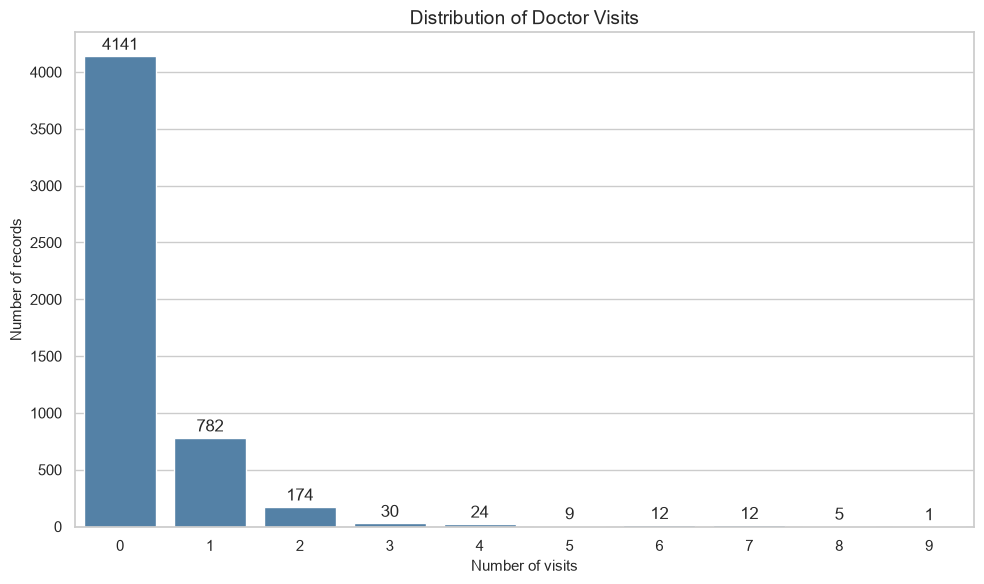

,percent_of_records
visits,
0,79.790
1,15.070
2,3.350
3,0.580
4,0.460
5,0.170
6,0.230
7,0.230
8,0.100


In [8]:
visit_counts = data["visits"].value_counts().sort_index()
ax = sns.barplot(color="steelblue", x=visit_counts.index.astype(str), y=visit_counts.values)
ax.set(title="Distribution of Doctor Visits", xlabel="Number of visits", ylabel="Number of records")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2)
plt.tight_layout()
plt.show()
display((visit_counts / len(data) * 100).round(2).rename("percent_of_records").to_frame())

**How to read this chart:** The tallest bar represents the most frequently recorded visit count. Check the percentage table to understand how much of the dataset each visit count represents; do not assume the sample represents every population.

## 8. Gender Profile
Compare the number of records by gender and the average visit count in each group.

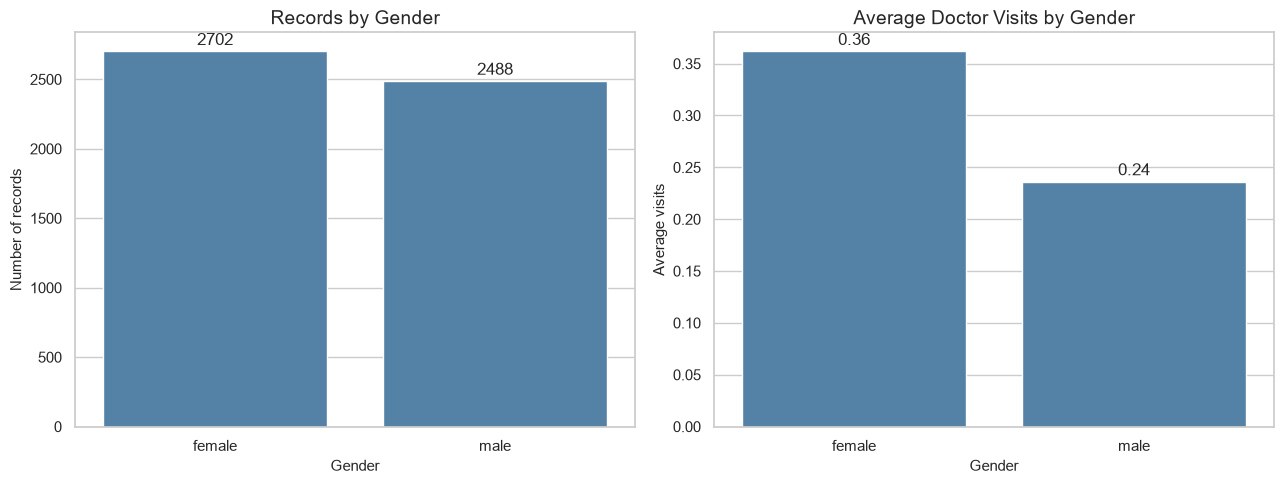

,count,mean,median
gender,,,
female,2702,0.362,0.000
male,2488,0.236,0.000


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
gender_counts = data["gender"].value_counts()
sns.barplot(color="steelblue", x=gender_counts.index, y=gender_counts.values, ax=axes[0])
axes[0].set(title="Records by Gender", xlabel="Gender", ylabel="Number of records")
gender_visits = data.groupby("gender", observed=True)["visits"].mean().sort_values(ascending=False)
sns.barplot(color="steelblue", x=gender_visits.index, y=gender_visits.values, ax=axes[1])
axes[1].set(title="Average Doctor Visits by Gender", xlabel="Gender", ylabel="Average visits")
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f" if ax is axes[1] else "%.0f", padding=2)
plt.tight_layout()
plt.show()
display(data.groupby("gender", observed=True)["visits"].agg(["count", "mean", "median"]).round(3))

## 9. Age-Level Analysis
The guide states that age is stored as a numerical/decimal value but does not specify a unit. We use broad data-based bins only to compare recorded levels.

,age_group,count,mean,median
0,Lower recorded age level,1965,0.206,0.000
1,Lower-middle level,970,0.252,0.000
2,Upper-middle level,529,0.342,0.000
3,Higher recorded age level,1726,0.427,0.000


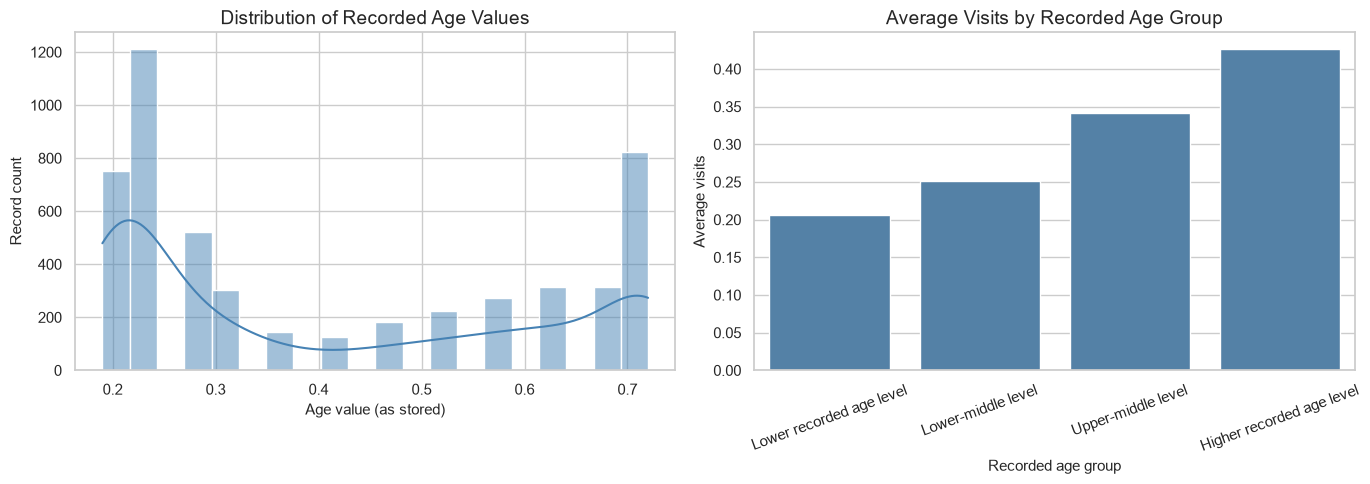

In [10]:
data["age_group"] = pd.cut(
    data["age"],
    bins=[-np.inf, 0.25, 0.40, 0.55, np.inf],
    labels=["Lower recorded age level", "Lower-middle level", "Upper-middle level", "Higher recorded age level"],
    include_lowest=True
)
age_visits = data.groupby("age_group", observed=False)["visits"].agg(["count", "mean", "median"]).reset_index()
display(age_visits.round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(color="steelblue", data=data, x="age", bins=20, kde=True, ax=axes[0])
axes[0].set(title="Distribution of Recorded Age Values", xlabel="Age value (as stored)", ylabel="Record count")
sns.barplot(color="steelblue", data=age_visits, x="age_group", y="mean", ax=axes[1])
axes[1].set(title="Average Visits by Recorded Age Group", xlabel="Recorded age group", ylabel="Average visits")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 10. Income-Level Analysis
Income is analyzed as a recorded numeric level because the dataset guide does not define a currency or unit.

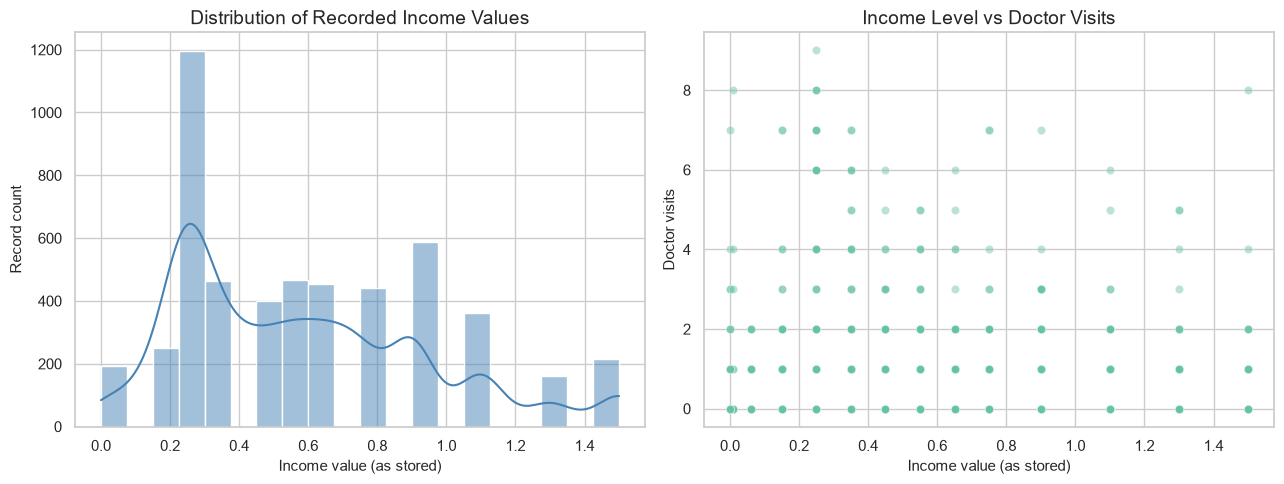

Correlation between recorded income and visits: -0.077


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(color="steelblue", data=data, x="income", bins=20, kde=True, ax=axes[0])
axes[0].set(title="Distribution of Recorded Income Values", xlabel="Income value (as stored)", ylabel="Record count")
sns.scatterplot(data=data, x="income", y="visits", alpha=0.45, ax=axes[1])
axes[1].set(title="Income Level vs Doctor Visits", xlabel="Income value (as stored)", ylabel="Doctor visits")
plt.tight_layout()
plt.show()
print("Correlation between recorded income and visits:", round(data[["income", "visits"]].corr().iloc[0,1], 3))

## 11. Illness and Doctor Visits
Compare recorded illness counts with the average number of doctor visits.

,illness,count,mean,median
0,0,1554,0.079,0.000
1,1,1638,0.295,0.000
2,2,946,0.404,0.000
3,3,542,0.421,0.000
4,4,274,0.577,0.000
5,5,236,0.814,0.000


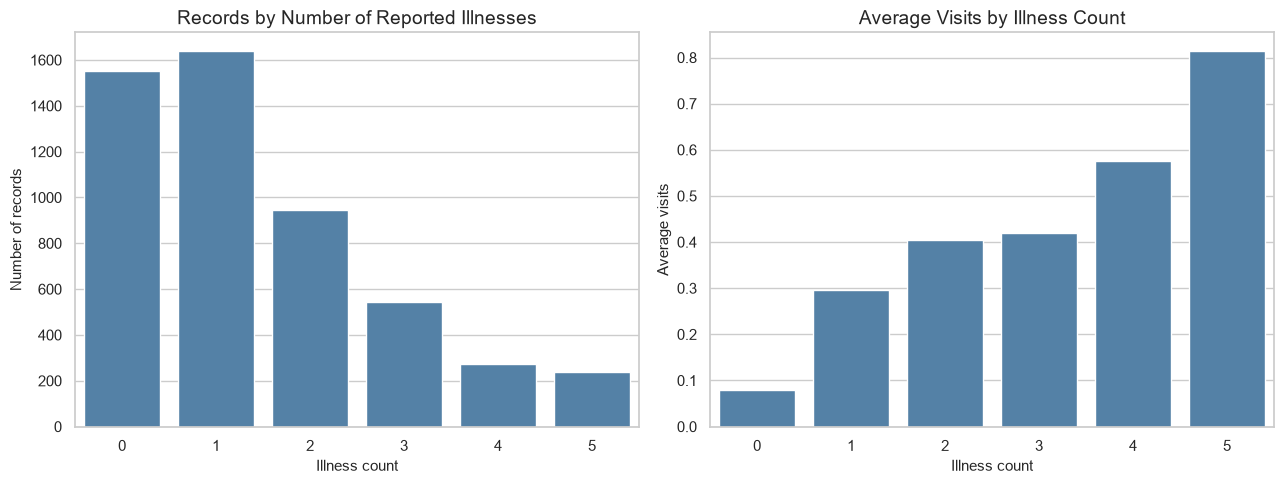

In [12]:
illness_summary = data.groupby("illness", observed=True)["visits"].agg(["count", "mean", "median"]).reset_index()
display(illness_summary.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(color="steelblue", data=data, x="illness", ax=axes[0])
axes[0].set(title="Records by Number of Reported Illnesses", xlabel="Illness count", ylabel="Number of records")
sns.barplot(color="steelblue", data=illness_summary, x="illness", y="mean", ax=axes[1])
axes[1].set(title="Average Visits by Illness Count", xlabel="Illness count", ylabel="Average visits")
plt.tight_layout()
plt.show()

## 12. Health Measure and Reduced Activity
Explore how the recorded health value and days of reduced activity relate to doctor visits. The dataset guide does not define the direction or units of the health score, so avoid interpreting a higher score as better or worse without additional documentation.

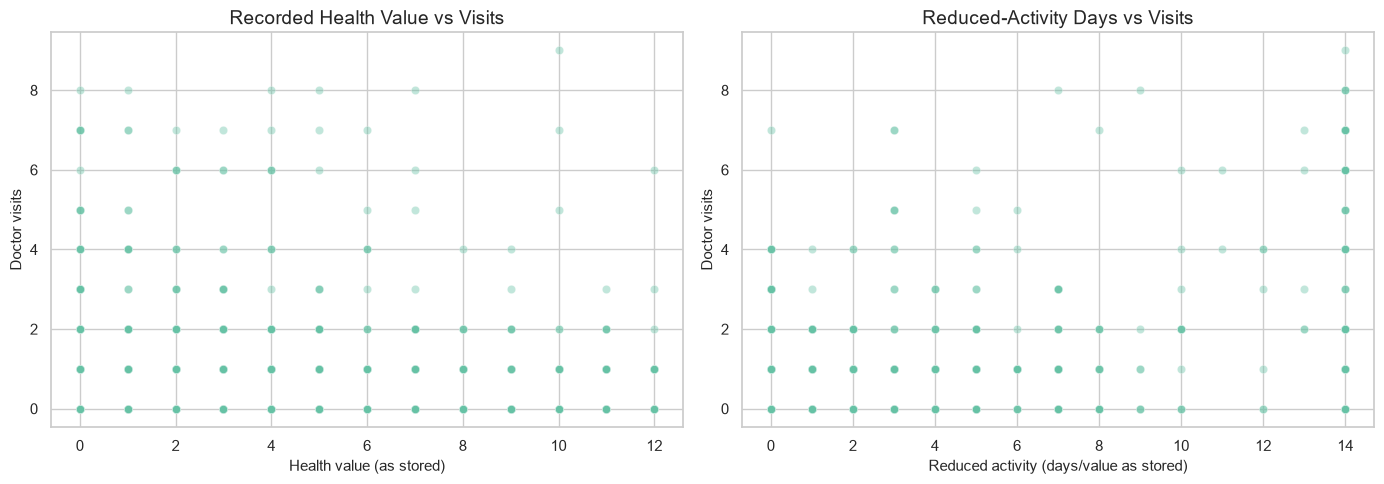

Correlation with visits:


,health,reduced,visits
health,1.000,0.280,0.193
reduced,0.280,1.000,0.419
visits,0.193,0.419,1.000


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=data, x="health", y="visits", alpha=0.4, ax=axes[0])
axes[0].set(title="Recorded Health Value vs Visits", xlabel="Health value (as stored)", ylabel="Doctor visits")
sns.scatterplot(data=data, x="reduced", y="visits", alpha=0.4, ax=axes[1])
axes[1].set(title="Reduced-Activity Days vs Visits", xlabel="Reduced activity (days/value as stored)", ylabel="Doctor visits")
plt.tight_layout()
plt.show()
print("Correlation with visits:")
display(data[["health", "reduced", "visits"]].corr().round(3))

## 13. Chronic Conditions
Compare visits for the two chronic-condition indicators (`nchronic` and `lchronic`) separately. The guide describes these as chronic-condition flags, but does not give more detailed clinical definitions.

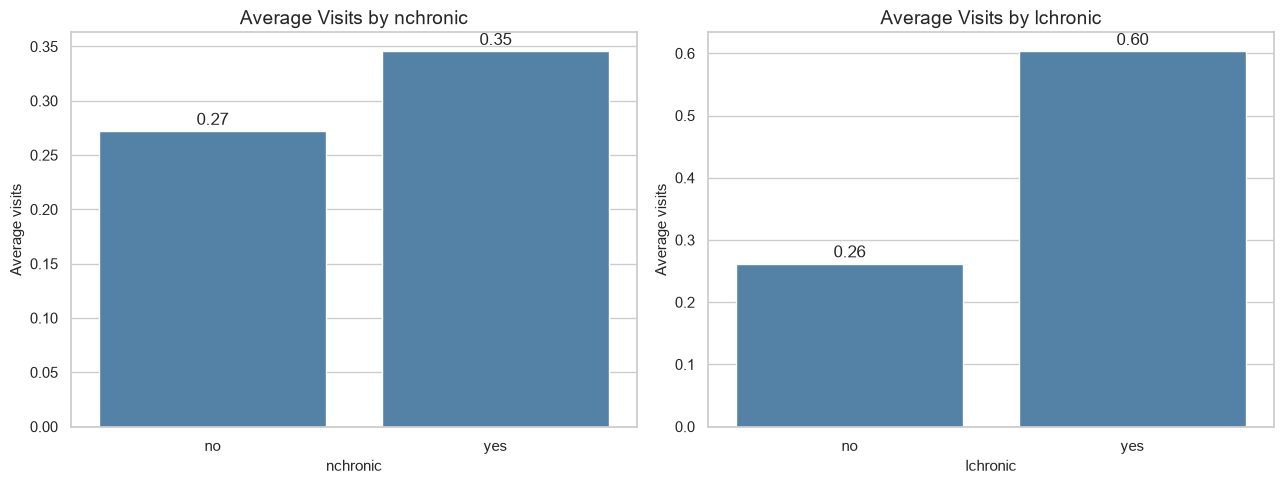

\nnchronic group summary


,count,mean,median
nchronic,,,
no,3098,0.272,0.000
yes,2092,0.346,0.000


\nlchronic group summary


,count,mean,median
lchronic,,,
no,4585,0.262,0.000
yes,605,0.603,0.000


In [14]:
chronic_cols = ["nchronic", "lchronic"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for col, ax in zip(chronic_cols, axes):
    summary = data.groupby(col, observed=True)["visits"].mean().reindex(["no", "yes"])
    sns.barplot(color="steelblue", x=summary.index, y=summary.values, ax=ax)
    ax.set(title=f"Average Visits by {col}", xlabel=col, ylabel="Average visits")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=2)
plt.tight_layout()
plt.show()
for col in chronic_cols:
    print(f"\\n{col} group summary")
    display(data.groupby(col, observed=True)["visits"].agg(["count", "mean", "median"]).round(3))

## 14. Healthcare Support and Doctor Visits
Explore average visits across private healthcare, free/low-income support (`freepoor`), and repatriation-related support (`freerepat`). These comparisons describe the sample only; they do not show whether a support program causes more or fewer visits.

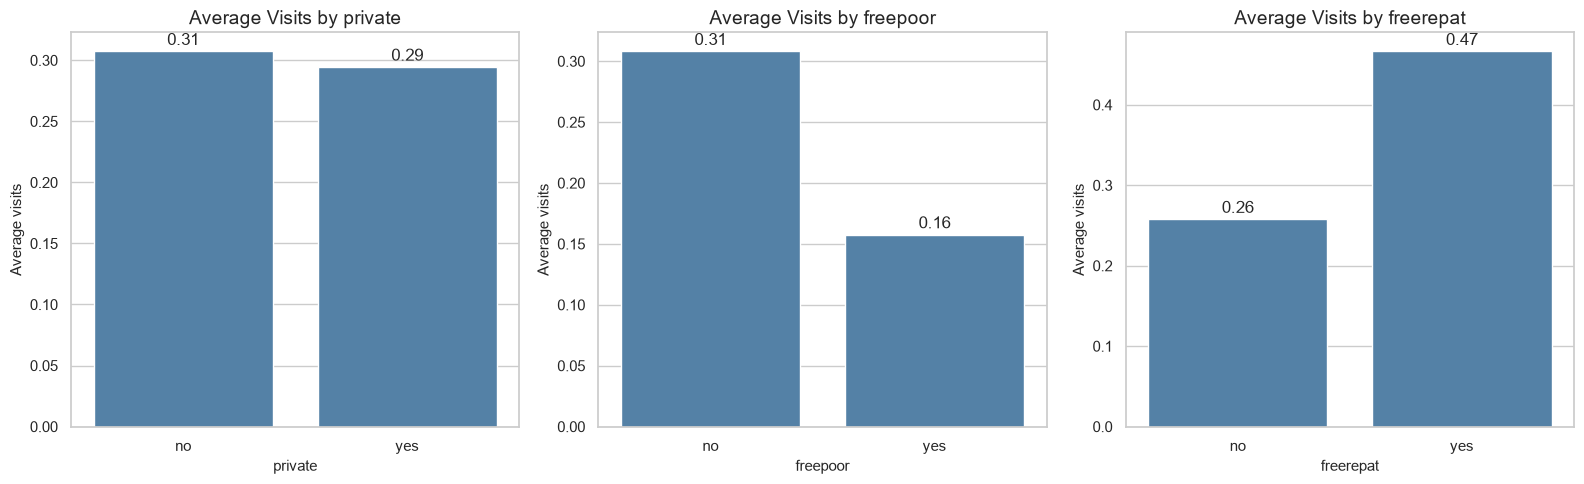

\nprivate group summary


,count,mean,median
private,,,
no,2892,0.307,0.000
yes,2298,0.295,0.000


\nfreepoor group summary


,count,mean,median
freepoor,,,
no,4968,0.308,0.000
yes,222,0.158,0.000


\nfreerepat group summary


,count,mean,median
freerepat,,,
no,4099,0.258,0.000
yes,1091,0.467,0.000


In [15]:
support_cols = ["private", "freepoor", "freerepat"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for col, ax in zip(support_cols, axes):
    summary = data.groupby(col, observed=True)["visits"].mean().reindex(["no", "yes"])
    sns.barplot(color="steelblue", x=summary.index, y=summary.values, ax=ax)
    ax.set(title=f"Average Visits by {col}", xlabel=col, ylabel="Average visits")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=2)
plt.tight_layout()
plt.show()
for col in support_cols:
    print(f"\\n{col} group summary")
    display(data.groupby(col, observed=True)["visits"].agg(["count", "mean", "median"]).round(3))

## 15. Doctor Visits by Multiple Factors
A box plot shows the spread of visit counts by selected categorical groups. This is useful because averages alone may hide variation and outliers.

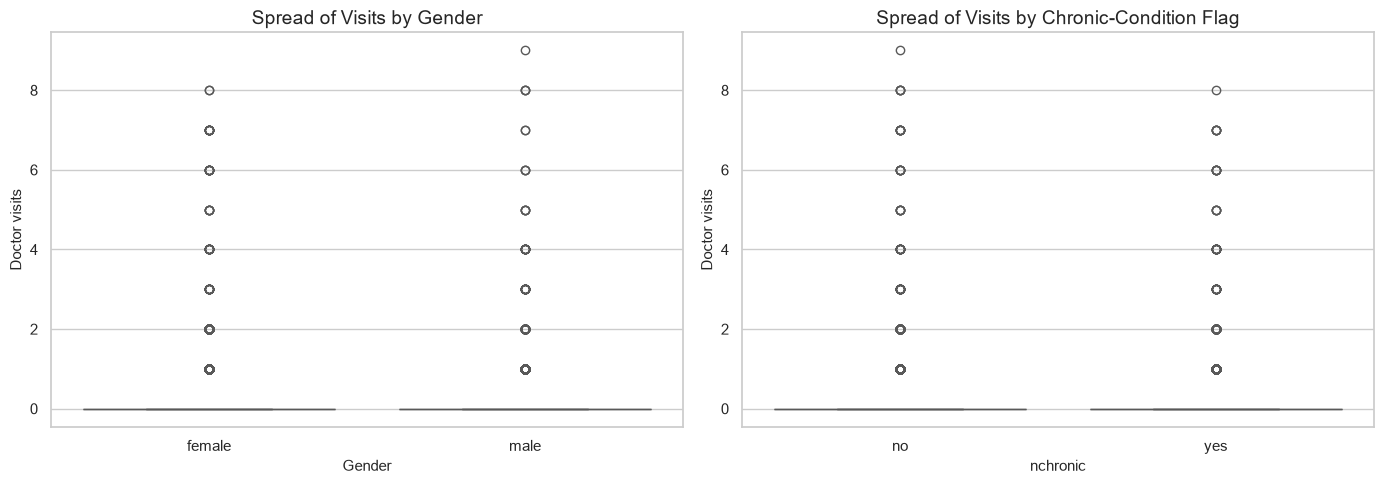

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=data, x="gender", y="visits", ax=axes[0])
axes[0].set(title="Spread of Visits by Gender", xlabel="Gender", ylabel="Doctor visits")
sns.boxplot(data=data, x="nchronic", y="visits", ax=axes[1])
axes[1].set(title="Spread of Visits by Chronic-Condition Flag", xlabel="nchronic", ylabel="Doctor visits")
plt.tight_layout()
plt.show()

## 16. Correlation Analysis
Correlations help identify linear relationships among numeric columns. They do not establish causation, and the recorded age/income scales should not be interpreted as physical units.

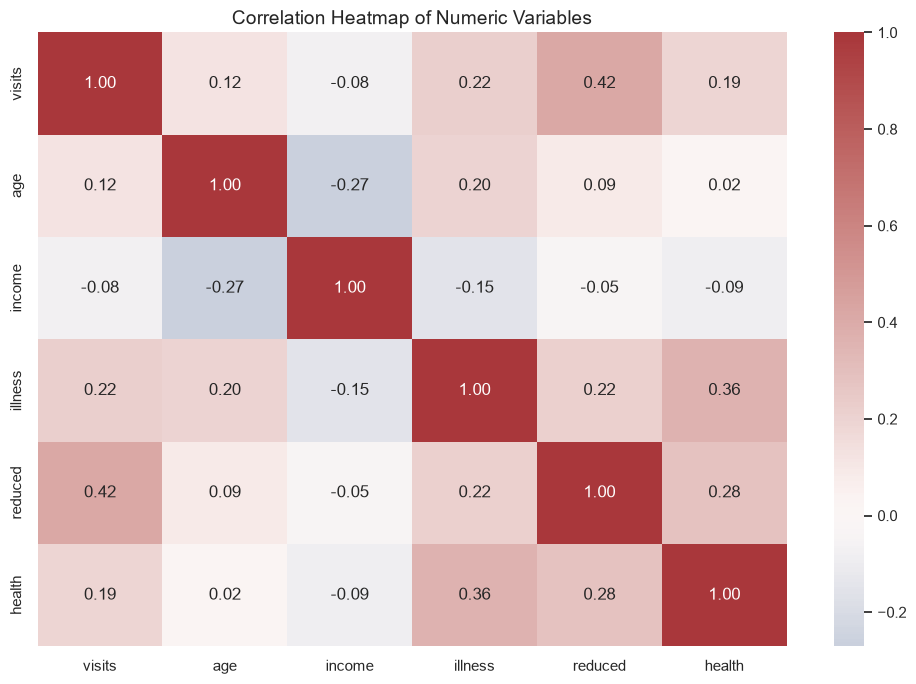

,correlation_with_visits
reduced,0.419
illness,0.224
health,0.193
age,0.125
income,-0.077


In [17]:
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
corr = data[numeric_cols].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="vlag", center=0, fmt=".2f", square=False)
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()
display(corr["visits"].drop("visits").sort_values(key=lambda s: s.abs(), ascending=False).to_frame("correlation_with_visits"))

## 17. Combined Summary Table
This table compares mean visits across selected categorical variables. Always review group counts alongside averages, especially for smaller groups.

In [18]:
group_summaries = []
for col in ["gender", "private", "freepoor", "freerepat", "nchronic", "lchronic"]:
    temp = data.groupby(col, observed=True)["visits"].agg(["count", "mean", "median"]).reset_index()
    temp.insert(0, "variable", col)
    temp = temp.rename(columns={col: "group"})
    group_summaries.append(temp)
combined_summary = pd.concat(group_summaries, ignore_index=True)
display(combined_summary.round(3))

,variable,group,count,mean,median
0,gender,female,2702,0.362,0.000
1,gender,male,2488,0.236,0.000
2,private,no,2892,0.307,0.000
3,private,yes,2298,0.295,0.000
4,freepoor,no,4968,0.308,0.000
5,freepoor,yes,222,0.158,0.000
6,freerepat,no,4099,0.258,0.000
7,freerepat,yes,1091,0.467,0.000
8,nchronic,no,3098,0.272,0.000
9,nchronic,yes,2092,0.346,0.000


## 18. Key Findings (Generated from the Dataset)
The following outputs are calculated directly from the loaded file. Use them to write a concise project summary without guessing or overstating the results.

In [19]:
most_common_visits = data["visits"].mode().iloc[0]
zero_pct = (data["visits"].eq(0).mean() * 100)
positive_pct = (data["visits"].gt(0).mean() * 100)
print(f"1. Dataset size: {len(data):,} records and {len(df.columns)} original columns.")
print(f"2. Average visits per record: {data['visits'].mean():.3f}; median: {data['visits'].median():.3f}.")
print(f"3. Most common visit count: {most_common_visits} visit(s), representing {(data['visits'].eq(most_common_visits).mean()*100):.1f}% of records.")
print(f"4. Records with zero visits: {zero_pct:.1f}%; records with at least one visit: {positive_pct:.1f}%.")
for col in ["gender", "private", "freepoor", "freerepat", "nchronic", "lchronic"]:
    s = data.groupby(col, observed=True)["visits"].mean().dropna()
    if len(s) >= 2:
        high_group = s.idxmax()
        low_group = s.idxmin()
        print(f"5. {col}: group '{high_group}' has the higher sample average ({s[high_group]:.3f}) versus '{low_group}' ({s[low_group]:.3f}).")

1. Dataset size: 5,190 records and 13 original columns.
2. Average visits per record: 0.302; median: 0.000.
3. Most common visit count: 0 visit(s), representing 79.8% of records.
4. Records with zero visits: 79.8%; records with at least one visit: 20.2%.
5. gender: group 'female' has the higher sample average (0.362) versus 'male' (0.236).
5. private: group 'no' has the higher sample average (0.307) versus 'yes' (0.295).
5. freepoor: group 'no' has the higher sample average (0.308) versus 'yes' (0.158).
5. freerepat: group 'yes' has the higher sample average (0.467) versus 'no' (0.258).
5. nchronic: group 'yes' has the higher sample average (0.346) versus 'no' (0.272).
5. lchronic: group 'yes' has the higher sample average (0.603) versus 'no' (0.262).


## 19. Conclusion
This project uses exploratory data analysis to examine doctor visits in relation to demographic, financial, health, and healthcare-support variables. The frequency distribution describes how visits are spread across records, while grouped summaries and plots allow comparisons between patient categories. Numeric summaries and the correlation heatmap provide additional ways to inspect patterns in the recorded variables.

The notebook's exact findings are generated by running the analysis cells on the supplied dataset. Interpret differences as **associations within this dataset**, not proof that a factor causes doctor visits. Age and income units, health-score direction, the time period covered by visits, and the sampling methodology are not fully documented in the supplied guide, which limits interpretation and generalization.

### Recommendations for further work
- Obtain a data dictionary describing units, coding rules, time period, and sampling method.
- Check whether group differences remain after adjusting for other variables.
- If appropriate and supported by the data, use a count-data model for visit counts and validate its assumptions.
- Protect privacy and avoid publishing any personally identifiable or sensitive patient-level information.

### Learning outcomes
- Loaded and inspected a real-world style healthcare dataset using Pandas.
- Checked missing values, duplicates, data types, and categorical values.
- Created visualizations using Matplotlib and Seaborn.
- Compared visit patterns across selected variables.
- Practiced writing evidence-based conclusions and noting analytical limitations.

---
**Project:** Healthcare Analytics for Doctor Visits  
**Program context:** AICTE–TIRTC learning project  
**Tools:** Python · Pandas · NumPy · Matplotlib · Seaborn · Jupyter Notebook